In [1]:
! pip install numpy matplotlib scipy shapely
! pip install alphashape


  Using cached matplotlib-3.10.3-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (11 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.59.0-cp312-cp312-manylinux1_x86_64.manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_5_x86_64.whl.metadata (107 kB)
  Using cached kiwisolver-1.4.8-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (6.2 kB)
  Using cached pillow-11.3.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.0 kB)
  Using cached pyparsing-3.2.3-py3-none-any.whl.metadata (5.0 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 50.5 MB/s eta 0:00:00a 0:00:01
Using cached matplotlib-3.10.3-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (8.6 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.2/35.2 MB 68.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 55.8 MB/s eta 0:00:00
Using cached cycler-0.12.1-py3-none-any.whl

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import matplotlib.colors as mcolors

TypeError: Polygon.__new__() got an unexpected keyword argument 'closed'

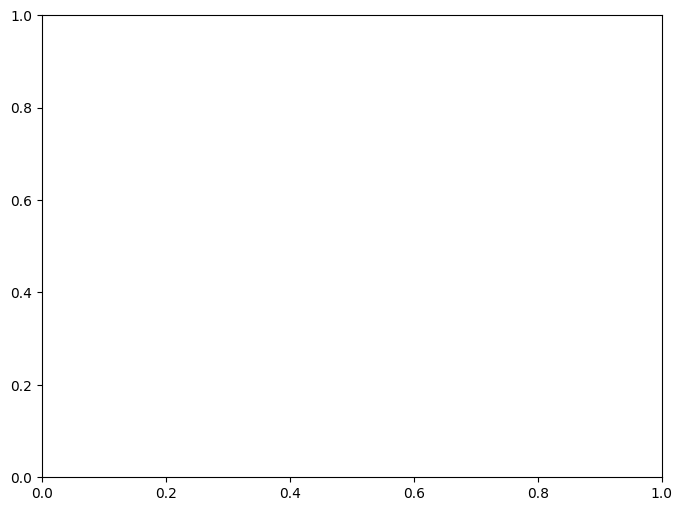

In [ ]:
def generate_curve_points(n_points=30, x_start=0.1, x_end=4.0, noise=0.05):
    eMBD = np.linspace(x_start, x_end, n_points)
    hl_gap = np.sqrt(eMBD) + np.random.normal(scale=noise, size=n_points)
    return hl_gap, eMBD

# Build a tube envelope (offset polygon) around the curve line
def create_envelope_line(x, y, thickness=0.1):
    # Create perpendicular offsets to form a tube
    dx = np.gradient(x)
    dy = np.gradient(y)
    norm = np.hypot(dx, dy)
    dx, dy = dx / norm, dy / norm

    # Upper and lower boundaries
    offset_x1 = x + thickness * dy
    offset_y1 = y - thickness * dx
    offset_x2 = x - thickness * dy
    offset_y2 = y + thickness * dx

    # Combine envelope path
    envelope_x = np.concatenate([offset_x1, offset_x2[::-1]])
    envelope_y = np.concatenate([offset_y1, offset_y2[::-1]])
    return envelope_x, envelope_y

# Plotting function
def plot_hl_gap_vs_embd(hl_gap, eMBD, save_path='hlgap_embd_tube.png'):
    fig, ax = plt.subplots(figsize=(8, 6))

    # Envelope around the trajectory
    env_x, env_y = create_envelope_line(hl_gap, eMBD, thickness=0.15)
    polygon = Polygon(np.column_stack([env_x, env_y]), color='orange', alpha=0.2, label='Explored Region')
    ax.add_patch(polygon)

    # Color gradient by sampling order
    norm = mcolors.Normalize(vmin=0, vmax=len(hl_gap))
    cmap = plt.cm.plasma

    for i, (x, y) in enumerate(zip(hl_gap, eMBD)):
        ax.scatter(x, y, color=cmap(norm(i)), s=40)

    ax.plot(hl_gap, eMBD, color='gray', linestyle='--', linewidth=1, alpha=0.6)

    # Labels and colorbar
    ax.set_xlabel("HL-gap (eV)")
    ax.set_ylabel("eMBD (a.u.)")
    ax.set_title("Exploration Path in HL-gap vs eMBD Space")

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax)
    cbar.set_label("Sampling Order")

    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend()
    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()

# Run everything
hl_gap, eMBD = generate_curve_points()
plot_hl_gap_vs_embd(hl_gap, eMBD)

In [3]:
def generate_parabolic_points(n_points=30, noise_scale=0.2):
    x = np.linspace(-3, 3, n_points)
    hl_gap = x**2 + np.random.normal(scale=noise_scale, size=n_points)
    eMBD = x + np.random.normal(scale=noise_scale, size=n_points)
    return hl_gap, eMBD

In [4]:
def create_envelope(x, y, alpha=0.2):
    points = np.column_stack((x, y))
    hull = ConvexHull(points)
    envelope_points = points[hull.vertices]
    polygon = Polygon(envelope_points)
    return polygon

In [5]:
def plot_hl_gap_vs_embd(hl_gap, eMBD, save_path='hlgap_embd_plot.png'):
    fig, ax = plt.subplots(figsize=(8, 6))

    # Draw envelope
    envelope = create_envelope(hl_gap, eMBD)
    patch = patches.Polygon(np.array(envelope.exterior.coords), closed=True, alpha=0.2, color='orange', label='Envelope')
    ax.add_patch(patch)

    # Color by novelty index (e.g., order)
    norm = mcolors.Normalize(vmin=0, vmax=len(hl_gap))
    cmap = plt.cm.viridis

    for i, (x, y) in enumerate(zip(hl_gap, eMBD)):
        ax.scatter(x, y, color=cmap(norm(i)), s=40)
    
    # Line connecting points
    ax.plot(hl_gap, eMBD, color='gray', alpha=0.5, linestyle='--', linewidth=1)

    ax.set_xlabel("HL-gap (eV)")
    ax.set_ylabel("eMBD (a.u.)")
    ax.set_title("Exploration in Molecular Property Space")
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax)
    cbar.set_label("Sampling Order")

    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend()
    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()



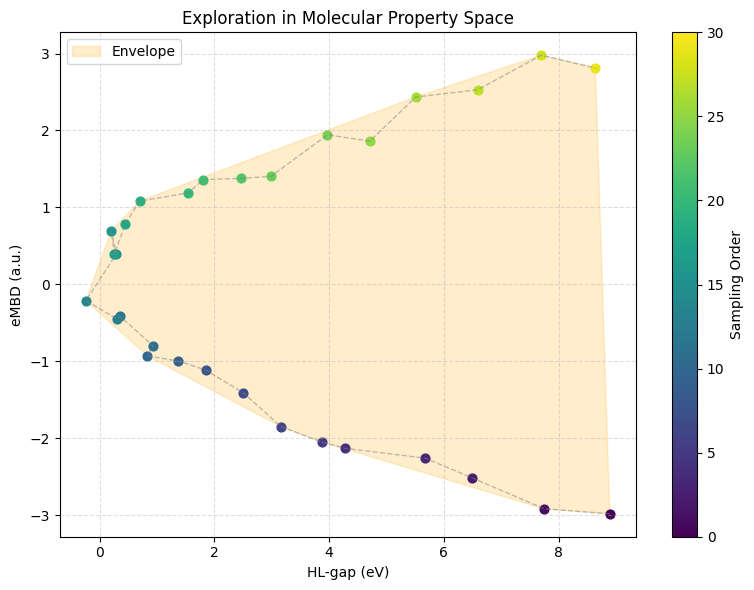

In [6]:
# Run it
hl_gap, eMBD = generate_parabolic_points()
plot_hl_gap_vs_embd(hl_gap, eMBD)